# Bài tập Lab 9


## Chuẩn bị
Chạy ô này trước, sau đó chạy các cell theo thứ tự. Nếu CSV ở nơi khác, điền đường dẫn vào các biến `DUONG_DAN_...`. Khi dùng Colab, tải CSV lên theo lời nhắc.

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, mean_absolute_error, silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import load_digits, load_sample_image
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC

# Để trống để tìm tự động; có thể chỉ định thư mục dữ liệu ở vị trí khác.
THU_MUC_DATA = os.environ.get("LAB9_DATA_DIR", "")
thu_muc_lab = Path(os.environ.get("LAB9_ROOT", Path.cwd())).resolve()
if "LAB9_ROOT" not in os.environ:
    if thu_muc_lab.name == "code": thu_muc_lab = thu_muc_lab.parent
    elif (thu_muc_lab / "09. MLP").is_dir(): thu_muc_lab /= "09. MLP"
thu_muc_hinh = thu_muc_lab / "figures"
thu_muc_hinh.mkdir(parents=True, exist_ok=True)

def tim_dataset(ten_tep):
    if THU_MUC_DATA:
        tep = Path(THU_MUC_DATA).expanduser() / ten_tep
        if tep.is_file(): return tep.resolve()
        raise FileNotFoundError(f"Khong tim thay {ten_tep} trong thu muc du lieu chi dinh.")
    for goc in [thu_muc_lab, Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        for tep in [goc / "09. MLP" / "data" / ten_tep, goc / "data" / ten_tep, goc / ten_tep]:
            if tep.is_file(): return tep.resolve()
    if "google.colab" in sys.modules:
        from google.colab import files
        print(f"Hay tai len tep {ten_tep}.")
        files.upload()
        if Path(ten_tep).is_file(): return Path(ten_tep).resolve()
    raise FileNotFoundError(f"Can tep {ten_tep}; dat vao data hoac chi dinh THU_MUC_DATA.")

def doc_csv(ten_tep):
    tep = tim_dataset(ten_tep)
    print("Dataset dang su dung:", tep.name)
    return pd.read_csv(tep)

def luu_hinh(ten_tep):
    plt.gcf().tight_layout()
    plt.savefig(thu_muc_hinh / ten_tep, dpi=160, bbox_inches="tight")
    print(f"Da luu hinh: figures/{ten_tep}")
    plt.show()
    plt.close()

def nhan_xet(*cac_cau):
    print("\nNHẬN XÉT VÀ GIẢI THÍCH")
    for cau in cac_cau: print(cau)

# Giữ nội dung cảnh báo hội tụ nhưng không in đường dẫn cài đặt cá nhân.
def canh_bao_ngan(message, category, filename, lineno, file=None, line=None):
    noi_dung = str(message)
    for goc in [thu_muc_lab, Path.home()]:
        for dang in [str(goc), goc.as_posix()]: noi_dung = noi_dung.replace(dang, "<thu_muc>")
    print(f"Canh bao {category.__name__}: {noi_dung}", file=file or sys.stdout)
warnings.showwarning = canh_bao_ngan

def chia_phan_loai(dac_trung, nhan):
    return train_test_split(dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan)


## Bài 1: Tự dự đoán bằng trọng số đã học

In [2]:
xor=doc_csv("xor.csv")
dac_trung_hoc,dac_trung_kiem_tra,nhan_hoc,nhan_kiem_tra=chia_phan_loai(xor[["x1","x2"]],xor.nhan)
mlp=MLPClassifier(hidden_layer_sizes=(8,),solver="lbfgs",max_iter=5000,random_state=0).fit(dac_trung_hoc,nhan_hoc)
nam_diem=dac_trung_kiem_tra.iloc[:5].to_numpy()
tong_lop_an=nam_diem@mlp.coefs_[0]+mlp.intercepts_[0]
lop_an=np.maximum(0,tong_lop_an)
logit=lop_an@mlp.coefs_[1]+mlp.intercepts_[1]
# Sigmoid ổn định số học bằng NumPy.
xac_suat_tay=np.exp(-np.logaddexp(0,-logit)).ravel()
xac_suat_thu_vien=mlp.predict_proba(dac_trung_kiem_tra.iloc[:5])[:,1]
print(pd.DataFrame({"chi_so":dac_trung_kiem_tra.index[:5],"tu_tinh":xac_suat_tay,"thu_vien":xac_suat_thu_vien,"sai_lech":np.abs(xac_suat_tay-xac_suat_thu_vien)}).to_string(index=False,float_format=lambda so:f"{so:.12f}"))
print("Kich thuoc trong so:",[trong_so.shape for trong_so in mlp.coefs_])
assert np.allclose(xac_suat_tay,xac_suat_thu_vien,atol=1e-12,rtol=1e-10)
nhan_xet("Ma trận đầu vào 5×2 nhân trọng số 2×8, cộng 8 hệ số chặn để ra tổng đầu vào của 8 nơ-ron. ReLU lấy max(0,z) theo từng phần tử; lớp ra nhân trọng số 8×1 và cộng một hệ số chặn.",
 "Sigmoid biến logit của lớp ra thành xác suất lớp 1. coefs_ chứa trọng số, intercepts_ chứa hệ số chặn đã học. Lan truyền tiến chỉ tính dự đoán, không cập nhật các trọng số này.",
 f"Sai lệch lớn nhất là {np.max(np.abs(xac_suat_tay-xac_suat_thu_vien)):.3e}, khớp thư viện trong sai số số thực. Mạng nhị phân có một đầu ra sigmoid, không phải tám xác suất hay một đầu ra ReLU. Dùng đúng thứ tự cột và đúng năm mẫu của tập kiểm tra như phần thực hành.")


Dataset dang su dung: xor.csv
 chi_so        tu_tinh       thu_vien       sai_lech
    338 0.017959280395 0.017959280395 0.000000000000
    342 0.999457305053 0.999457305053 0.000000000000
     40 0.801705590116 0.801705590116 0.000000000000
    231 0.135632987822 0.135632987822 0.000000000000
    242 0.956438894064 0.956438894064 0.000000000000
Kich thuoc trong so: [(2, 8), (8, 1)]

NHẬN XÉT VÀ GIẢI THÍCH
Ma trận đầu vào 5×2 nhân trọng số 2×8, cộng 8 hệ số chặn để ra tổng đầu vào của 8 nơ-ron. ReLU lấy max(0,z) theo từng phần tử; lớp ra nhân trọng số 8×1 và cộng một hệ số chặn.
Sigmoid biến logit của lớp ra thành xác suất lớp 1. coefs_ chứa trọng số, intercepts_ chứa hệ số chặn đã học. Lan truyền tiến chỉ tính dự đoán, không cập nhật các trọng số này.
Sai lệch lớn nhất là 1.110e-16, khớp thư viện trong sai số số thực. Mạng nhị phân có một đầu ra sigmoid, không phải tám xác suất hay một đầu ra ReLU. Dùng đúng thứ tự cột và đúng năm mẫu của tập kiểm tra như phần thực hành.


## Bài 2: Một mạng XOR khác

In [3]:
dau_vao=np.array([[0,0],[0,1],[1,0],[1,1]])
an_thu_nhat=np.maximum(0,dau_vao[:,0]-dau_vao[:,1])
an_thu_hai=np.maximum(0,dau_vao[:,1]-dau_vao[:,0])
dau_ra=an_thu_nhat+an_thu_hai
xor_that=np.logical_xor(dau_vao[:,0],dau_vao[:,1]).astype(int)
print(pd.DataFrame({"x1":dau_vao[:,0],"x2":dau_vao[:,1],"h1":an_thu_nhat,"h2":an_thu_hai,"y":dau_ra,"XOR":xor_that}).to_string(index=False))
assert np.array_equal(dau_ra,xor_that)
nhan_xet("Khi hai bit bằng nhau, cả hai hiệu đều bằng 0 nên h1=h2=0 và y=0. Với (1,0), h1=1 và h2=0; với (0,1), h1=0 và h2=1. Vì vậy y=1 đúng khi hai bit khác nhau, khớp cả bốn trường hợp XOR.",
 "Hai ReLU giữ riêng phần dương của hai hiệu trái dấu. Tổng của chúng bằng |x1-x2|. Trên đầu vào nhị phân, trị tuyệt đối này chính là XOR; trên số thực bất kỳ, nó chỉ là khoảng cách tuyệt đối và không còn là phép XOR logic.",
 "Lớp ra ở mạng được cho là phép cộng tuyến tính, không có sigmoid. Tính phi tuyến cần thiết nằm ở hai ReLU; nếu bỏ ReLU thì hai hiệu triệt tiêu và đầu ra luôn bằng 0. Đây là mạng đặt trọng số thủ công, không có bước huấn luyện.")


 x1  x2  h1  h2  y  XOR
  0   0   0   0  0    0
  0   1   0   1  1    1
  1   0   1   0  1    1
  1   1   0   0  0    0

NHẬN XÉT VÀ GIẢI THÍCH
Khi hai bit bằng nhau, cả hai hiệu đều bằng 0 nên h1=h2=0 và y=0. Với (1,0), h1=1 và h2=0; với (0,1), h1=0 và h2=1. Vì vậy y=1 đúng khi hai bit khác nhau, khớp cả bốn trường hợp XOR.
Hai ReLU giữ riêng phần dương của hai hiệu trái dấu. Tổng của chúng bằng |x1-x2|. Trên đầu vào nhị phân, trị tuyệt đối này chính là XOR; trên số thực bất kỳ, nó chỉ là khoảng cách tuyệt đối và không còn là phép XOR logic.
Lớp ra ở mạng được cho là phép cộng tuyến tính, không có sigmoid. Tính phi tuyến cần thiết nằm ở hai ReLU; nếu bỏ ReLU thì hai hiệu triệt tiêu và đầu ra luôn bằng 0. Đây là mạng đặt trọng số thủ công, không có bước huấn luyện.


## Bài 3: So các hàm kích hoạt

In [4]:
trang=doc_csv("hai_vang_trang.csv")
dac_trung_hoc,dac_trung_kiem_tra,nhan_hoc,nhan_kiem_tra=chia_phan_loai(trang[["x1","x2"]],trang.nhan)
ket_qua=[]
for kich_hoat in ["logistic","tanh","relu"]:
    mang=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(100,100),alpha=1.0,activation=kich_hoat,solver="lbfgs",max_iter=20000,random_state=0))
    mang.fit(dac_trung_hoc,nhan_hoc)
    ket_qua.append({"kich_hoat":kich_hoat,"accuracy_hoc":mang.score(dac_trung_hoc,nhan_hoc),"accuracy_kiem_tra":mang.score(dac_trung_kiem_tra,nhan_kiem_tra)})
bang=pd.DataFrame(ket_qua); print(bang.to_string(index=False))
tot=bang.loc[np.isclose(bang.accuracy_kiem_tra,bang.accuracy_kiem_tra.max()),"kich_hoat"].tolist()
nhan_xet(f"Trong lần chia và các tham số đã cố định, {', '.join(tot)} có accuracy kiểm tra cao nhất: {bang.accuracy_kiem_tra.max():.4f}.",
 "Logistic và tanh có vùng bão hòa; ReLU bằng 0 ở phía âm và tuyến tính ở phía dương. Chúng tạo biểu diễn khác nhau nên kết quả có thể khác dù cùng kiến trúc. Khoảng cách accuracy học và kiểm tra giúp nhận diện học vẹt, nhưng một lần chia không chứng minh hàm nào tốt nhất cho mọi dữ liệu. Nếu cần lựa chọn để triển khai, chọn bằng kiểm định chéo trên tập học.")


Dataset dang su dung: hai_vang_trang.csv


kich_hoat  accuracy_hoc  accuracy_kiem_tra
 logistic      0.840000           0.853333
     tanh      0.866667           0.906667
     relu      0.880000           0.906667

NHẬN XÉT VÀ GIẢI THÍCH
Trong lần chia và các tham số đã cố định, tanh, relu có accuracy kiểm tra cao nhất: 0.9067.
Logistic và tanh có vùng bão hòa; ReLU bằng 0 ở phía âm và tuyến tính ở phía dương. Chúng tạo biểu diễn khác nhau nên kết quả có thể khác dù cùng kiến trúc. Khoảng cách accuracy học và kiểm tra giúp nhận diện học vẹt, nhưng một lần chia không chứng minh hàm nào tốt nhất cho mọi dữ liệu. Nếu cần lựa chọn để triển khai, chọn bằng kiểm định chéo trên tập học.


## Bài 4: Tốc độ học

Dang hoc voi learning_rate_init=0.0001


Dang hoc voi learning_rate_init=0.001


Dang hoc voi learning_rate_init=0.01


Dang hoc voi learning_rate_init=0.1


 toc_do_hoc  so_vong  loss_cuoi  accuracy_kiem_tra
     0.0001      582   0.018928           0.988889
     0.0010      144   0.005210           0.984444
     0.0100       38   0.001077           0.977778
     0.1000       30   0.112580           0.962222


Da luu hinh: figures/toc_do_hoc.png


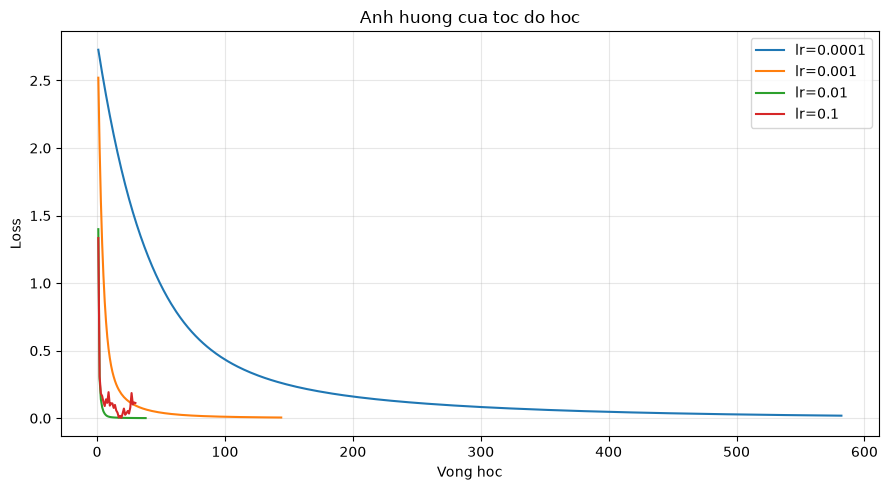


NHẬN XÉT VÀ GIẢI THÍCH
Tốc độ học nhỏ cập nhật trọng số ít mỗi bước, có thể cần nhiều vòng; tốc độ lớn có thể vượt qua vùng nghiệm tốt, dao động hoặc dừng với nghiệm kém. Đọc bốn đường loss cùng số vòng và accuracy thực tế trong bảng, không mặc định đường nào cũng giảm đều.
Trong lần thử, loss cuối nằm từ 0.001077 đến 0.112580; accuracy kiểm tra từ 0.9622 đến 0.9889.
Loss là mục tiêu tối ưu trên tập học, không phải accuracy trên tập kiểm tra. Dừng trước max_iter phản ánh tiêu chí dung sai, không chứng minh tìm được tối ưu toàn cục. Nếu có cảnh báo hội tụ, cần ghi nhận rằng nghiệm còn bị giới hạn bởi số vòng, không che cảnh báo đó.


In [5]:
anh,nhan=load_digits(return_X_y=True)
anh_hoc,anh_kiem_tra,nhan_hoc,nhan_kiem_tra=chia_phan_loai(anh,nhan)
ket_qua=[]; plt.figure(figsize=(9,5))
for toc_do in [0.0001,0.001,0.01,0.1]:
    print(f"Dang hoc voi learning_rate_init={toc_do}",flush=True)
    mang=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(100,),learning_rate_init=toc_do,max_iter=1000,random_state=0))
    mang.fit(anh_hoc,nhan_hoc); mlp=mang[-1]
    ket_qua.append({"toc_do_hoc":toc_do,"so_vong":mlp.n_iter_,"loss_cuoi":mlp.loss_,"accuracy_kiem_tra":mang.score(anh_kiem_tra,nhan_kiem_tra)})
    plt.plot(range(1,len(mlp.loss_curve_)+1),mlp.loss_curve_,label=f"lr={toc_do}")
bang=pd.DataFrame(ket_qua); print(bang.to_string(index=False))
plt.xlabel("Vong hoc"); plt.ylabel("Loss"); plt.title("Anh huong cua toc do hoc"); plt.legend(); plt.grid(alpha=0.3)
luu_hinh("toc_do_hoc.png")
nhan_xet("Tốc độ học nhỏ cập nhật trọng số ít mỗi bước, có thể cần nhiều vòng; tốc độ lớn có thể vượt qua vùng nghiệm tốt, dao động hoặc dừng với nghiệm kém. Đọc bốn đường loss cùng số vòng và accuracy thực tế trong bảng, không mặc định đường nào cũng giảm đều.",
 f"Trong lần thử, loss cuối nằm từ {bang.loss_cuoi.min():.6f} đến {bang.loss_cuoi.max():.6f}; accuracy kiểm tra từ {bang.accuracy_kiem_tra.min():.4f} đến {bang.accuracy_kiem_tra.max():.4f}.",
 "Loss là mục tiêu tối ưu trên tập học, không phải accuracy trên tập kiểm tra. Dừng trước max_iter phản ánh tiêu chí dung sai, không chứng minh tìm được tối ưu toàn cục. Nếu có cảnh báo hội tụ, cần ghi nhận rằng nghiệm còn bị giới hạn bởi số vòng, không che cảnh báo đó.")


## Bài 5: Dò lưới cho mạng nơ-ron
12 tổ hợp × 5 fold; có thể mất nhiều thời gian.

In [6]:
anh,nhan=load_digits(return_X_y=True)
anh_hoc,anh_kiem_tra,nhan_hoc,nhan_kiem_tra=chia_phan_loai(anh,nhan)
mang=make_pipeline(StandardScaler(),MLPClassifier(max_iter=1000,random_state=0))
luoi={"mlpclassifier__hidden_layer_sizes":[(10,),(50,),(100,),(50,50)],"mlpclassifier__alpha":[0.0001,0.01,1]}
tim_kiem=GridSearchCV(mang,luoi,cv=5,scoring="accuracy",n_jobs=1,verbose=1,error_score="raise")
tim_kiem.fit(anh_hoc,nhan_hoc)
for tham_so,diem in zip(tim_kiem.cv_results_["params"],tim_kiem.cv_results_["mean_test_score"]):
    print(tham_so,f"accuracy_CV={diem:.6f}")
diem_mlp=tim_kiem.score(anh_kiem_tra,nhan_kiem_tra)
svm=SVC().fit(anh_hoc,nhan_hoc)  # Cùng SVM RBF gốc của phần thực hành.
diem_svm=svm.score(anh_kiem_tra,nhan_kiem_tra)
print("Tham so tot nhat:",tim_kiem.best_params_)
print(f"Accuracy CV={tim_kiem.best_score_:.6f}; kiem tra MLP={diem_mlp:.6f}; SVM={diem_svm:.6f}")
nhan_xet(f"Tổ hợp tốt nhất theo CV trên tập học là {tim_kiem.best_params_}. MLP "+("vượt" if diem_mlp>diem_svm else "bằng" if diem_mlp==diem_svm else "chưa vượt")+f" SVM trên cùng tập kiểm tra: {diem_mlp:.4f} so với {diem_svm:.4f}.",
 "Scaler nằm trong pipeline nên mỗi fold chỉ học trung bình và độ lệch chuẩn từ phần huấn luyện của fold đó. Sau khi chọn bằng điểm CV, GridSearchCV học lại tổ hợp tốt nhất trên toàn bộ tập học rồi mới đánh giá tập kiểm tra. Không dùng điểm kiểm tra để đổi tổ hợp hay phá hòa.",
 "Độ rộng và độ sâu quyết định số tham số; alpha điều chỉnh phạt L2. Mạng lớn hơn không tự bảo đảm tổng quát tốt hơn. Đây là kết quả trên một cách chia cố định, không chứng minh MLP hay SVM luôn tốt hơn.")


Fitting 5 folds for each of 12 candidates, totalling 60 fits


{'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (10,)} accuracy_CV=0.948016
{'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (50,)} accuracy_CV=0.974013
{'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (100,)} accuracy_CV=0.975498
{'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (50, 50)} accuracy_CV=0.968063
{'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (10,)} accuracy_CV=0.948757
{'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (50,)} accuracy_CV=0.975498
{'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (100,)} accuracy_CV=0.975498
{'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (50, 50)} accuracy_CV=0.968063
{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (10,)} accuracy_CV=0.965108
{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)} accuracy_CV=0.978469
{'mlpclassifier__alpha': 1, 'm

## Bài 6: Mạng nơ-ron cho hồi quy

In [7]:
nha=doc_csv("gia_nha.csv")
dien_tich_hoc,dien_tich_kiem_tra,gia_hoc,gia_kiem_tra=train_test_split(nha[["dien_tich"]],nha.gia,test_size=0.2,random_state=42)
mang=make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(20,),max_iter=5000,random_state=0))
thang=LinearRegression()
can_moi=pd.DataFrame({"dien_tich":[250.0]})
diem={}; gia_moi={}
for ten,mo_hinh in [("MLP",mang),("Hoi quy tuyen tinh",thang)]:
    mo_hinh.fit(dien_tich_hoc,gia_hoc)
    diem[ten]=mean_absolute_error(gia_kiem_tra,mo_hinh.predict(dien_tich_kiem_tra))
    gia_moi[ten]=float(mo_hinh.predict(can_moi)[0])
    print(f"{ten}: MAE={diem[ten]:.4f} ty dong; gia 250 m2={gia_moi[ten]:.4f} ty dong")
print(f"Khoang dien tich hoc: {dien_tich_hoc.dien_tich.min():.1f} - {dien_tich_hoc.dien_tich.max():.1f} m2")
nhan_xet(f"MAE kiểm tra của MLP là {diem['MLP']:.4f} tỷ, của hồi quy tuyến tính là {diem['Hoi quy tuyen tinh']:.4f} tỷ. Cả hai dùng diện tích làm đặc trưng và cùng cách chia dữ liệu như bài 1; scaler của MLP chỉ fit trên tập học.",
 f"Ở 250 m², MLP dự đoán {gia_moi['MLP']:.4f} tỷ và đường thẳng dự đoán {gia_moi['Hoi quy tuyen tinh']:.4f} tỷ. Nếu 250 m² vượt phạm vi học đã in, đây là ngoại suy.",
 "Mạng ReLU là hàm tuyến tính từng đoạn và có thể ngoại suy, nhưng độ dốc ngoài vùng học không được dữ liệu kiểm chứng. Hồi quy tuyến tính tiếp tục một xu hướng thẳng đã giả định, thường dễ diễn giải hơn. Không có giá thật của căn 250 m² nên không thể kết luận chắc mô hình nào dự đoán đúng hơn ở đó chỉ từ hai giá dự đoán; MAE trong tập kiểm tra cũng không chứng minh chất lượng ngoại suy.")


Dataset dang su dung: gia_nha.csv


MLP: MAE=0.5008 ty dong; gia 250 m2=28.1758 ty dong
Hoi quy tuyen tinh: MAE=0.2578 ty dong; gia 250 m2=19.9139 ty dong
Khoang dien tich hoc: 37.6 - 117.5 m2

NHẬN XÉT VÀ GIẢI THÍCH
MAE kiểm tra của MLP là 0.5008 tỷ, của hồi quy tuyến tính là 0.2578 tỷ. Cả hai dùng diện tích làm đặc trưng và cùng cách chia dữ liệu như bài 1; scaler của MLP chỉ fit trên tập học.
Ở 250 m², MLP dự đoán 28.1758 tỷ và đường thẳng dự đoán 19.9139 tỷ. Nếu 250 m² vượt phạm vi học đã in, đây là ngoại suy.
Mạng ReLU là hàm tuyến tính từng đoạn và có thể ngoại suy, nhưng độ dốc ngoài vùng học không được dữ liệu kiểm chứng. Hồi quy tuyến tính tiếp tục một xu hướng thẳng đã giả định, thường dễ diễn giải hơn. Không có giá thật của căn 250 m² nên không thể kết luận chắc mô hình nào dự đoán đúng hơn ở đó chỉ từ hai giá dự đoán; MAE trong tập kiểm tra cũng không chứng minh chất lượng ngoại suy.
